# setup + imports

In [1]:
import os
import numpy as np
from PIL import Image
import pandas as pd 
import matplotlib.pyplot as plt
from scipy import ndimage


# subtask 1

In [2]:
chars = ['A', 'B', 'E', 'F', 'O', 'I', '0', '1', '2', '4', '7', '8']
letters = ['A', 'B', 'E', 'F', 'O', 'I']
numbers = ['0', '1', '2', '4', '7', '8']

In [3]:
def load_pairs(ch):
    pairs = []
    for name in sorted(os.listdir('amprente_digitale')):
        if name.startswith(ch + '_'):
            img = np.array(Image.open(os.path.join('amprente_digitale', name)).convert('L'), dtype=np.float32)
            pairs.append((img[:, :42], img[:, 42:]))  
    return pairs

angles = {}
for ch in chars:
    pairs = load_pairs(ch)
    bestangle = None
    besterr = None
    for unghi in range(-30, 31):
        err = 0
        for good, bad in pairs:
            rotated = ndimage.rotate(good, unghi, reshape=False)
            err += np.abs(rotated-bad).mean()
        if besterr is None:
            besterr = err
            bestangle = unghi
        else:
            if besterr > err:
                besterr = err
                bestangle = unghi
    angles[ch] = bestangle
        

# subtask 2

In [4]:
noise = {}
origs = {}
for ch in chars:
    diffs = []
    pairs = load_pairs(ch)
    for good, bad in pairs:
        fixbad = ndimage.rotate(bad, -angles[ch], reshape=False)
        diffs.append(fixbad[7:35, 7:35] - good[7:35, 7:35])
        origs[ch] = good
    diffs = np.array(diffs)
    noise[ch] = diffs.mean(axis=0)

# subtask 3

In [5]:
def load_refs(ch):
    refs = []
    for name in sorted(os.listdir('imagini_antrenare')):
        if name.startswith(ch + '_'):
            img = np.array(Image.open(os.path.join('imagini_antrenare', name)).convert('L'), dtype=np.float32)
            refs.append(img)
    return np.array(refs) 

def load_sus():
    susimgs = []
    for name in sorted(os.listdir('imagini_suspecte')):
        if name.startswith('task3'):
            img = np.array(Image.open(os.path.join('imagini_suspecte', name)).convert('L'), dtype=np.float32)
            susimgs.append(img)
    return susimgs

refs = {}
for ch in chars:
    refs[ch] = load_refs(ch)

In [6]:
def closest(img):
    bestmatch = None
    bestdist = None
    for ch in chars:
        fix = ndimage.rotate(img, -angles[ch], reshape=False)
        fix = fix[7:35, 7:35] - noise[ch]
        dist = np.abs(refs[ch] - fix).mean(axis=(1, 2)).min()
        if bestdist is None or dist < bestdist:
            bestmatch = ch
            bestdist = dist
    return bestmatch, bestdist

dists = []
matches = []
for img in load_sus():
    bestmatch, bestdist = closest(img)
    matches.append(bestmatch)
    dists.append(bestdist)



In [7]:
cal_dists = []
correct = 0
for ch in chars:
    for good, bad in load_pairs(ch):
        match, dist = closest(bad)
        cal_dists.append(dist)
        if match == ch:
            correct += 1

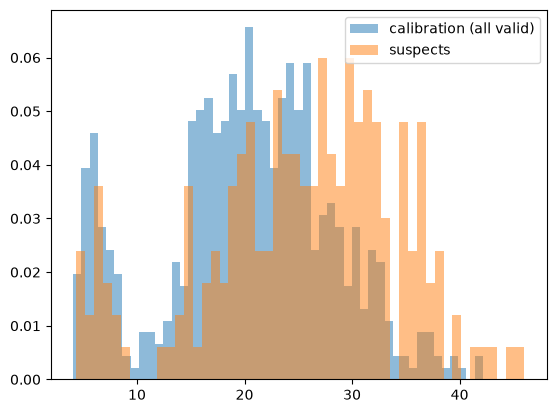

In [8]:
plt.hist(cal_dists, bins=50, alpha=0.5, density=True, label='calibration (all valid)')
plt.hist(dists, bins=50, alpha=0.5, density=True, label='suspects')
plt.legend()
plt.show()

In [9]:
threshold = 26

In [10]:
answers3 = []
for i in range(len(matches)):
    if dists[i] < threshold:
        answers3.append(1)
    else:
        answers3.append(0)

# subtask 4

In [11]:
def load_parole():
    parole = []
    for name in sorted(os.listdir('parole')):
        if name.startswith('task4'):
            img = np.array(Image.open(os.path.join('parole', name)).convert('L'), dtype=np.float32)
            parole.append(img)
    return parole

In [12]:
parole = load_parole()

answers4 = []
for img in parole:
    lenpass = int(img.shape[1] / img.shape[0])
    nrlit = 0
    nrcif = 0
    for i in range(lenpass):
        oneimg = img[:, (i*img.shape[0]):((i+1)*img.shape[0])]
        bestmatch, bestdist = closest(oneimg)
        if bestmatch in letters:
            nrlit += 1
        else:
            nrcif += 1
    if (nrlit < nrcif):
        answers4.append('digits')
    else:
        answers4.append('letters')

# submisie

In [13]:
def save_amprente_digitale(rotation_angles, noise_patterns, output_path="amprente_digitale.npy"):
    required_chars = ["A", "B", "E", "F", "O", "I", "0", "1", "2", "4", "7", "8"]
    submission_dict = {}
    for ch in required_chars:
        if ch not in rotation_angles:
            raise ValueError(f"Lipseste unghiul pentru caracterul '{ch}'")
        if ch not in noise_patterns:
            raise ValueError(f"Lipseste zgomotul pentru caracterul '{ch}'")
        noise = np.array(noise_patterns[ch])
        if noise.shape != (28, 28):
            raise ValueError(
                f"Zgomotul pentru '{ch}' trebuie sa aibÄƒ dimensiunea (28, 28), dar are {noise.shape}"
            )
        submission_dict[ch] = {
            "angle": float(rotation_angles[ch]),
            "noise": noise
        }
    np.save(output_path, submission_dict, allow_pickle=True)
    return submission_dict

rotation_angles = angles.copy()
noise_patterns = noise.copy()

save_amprente_digitale(rotation_angles, noise_patterns)

{'A': {'angle': -8.0,
  'noise': array([[ 5.68977384e-07, -1.93398155e-05,  6.02851578e-05,
           2.44152849e-04, -2.33709769e-04, -1.70654361e-03,
           3.07599036e-03, -1.18717505e-03,  2.38295761e-03,
           5.51512241e-02,  2.76156664e-02,  3.47135365e-02,
           3.01916748e-02, -1.09600261e-01, -5.46314359e-01,
          -6.86979234e-01, -8.71997774e-01, -1.54263213e-01,
           2.21753374e-01,  1.28255367e-01, -2.68585309e-02,
          -2.96276733e-02, -1.00747727e-01, -2.20179349e-01,
          -1.10208981e-01, -5.37636643e-03,  9.31287243e-04,
           1.10306764e-05],
         [-8.52879384e-06,  8.16786851e-05, -1.95750297e-04,
          -6.35947566e-04, -4.09551634e-04,  6.61496213e-03,
          -1.12928962e-02, -2.55811174e-04,  5.26969507e-03,
          -1.92635760e-01, -7.37557039e-02,  1.46623611e-01,
           2.17416823e-01,  1.01875804e-01,  1.24517834e+00,
           2.03353429e+00,  2.91047955e+00,  2.47945666e+00,
           1.33260393e+00,

In [14]:
sus_names = []
for name in sorted(os.listdir('imagini_suspecte')):
    if name.startswith('task3'):
        sus_names.append(name)

pass_names = []
for name in sorted(os.listdir('parole')):
    if name.endswith('.png'):
        pass_names.append(name)

rows = []
for i in range(len(sus_names)):
    rows.append({'file': sus_names[i], 'subtaskID': 3, 'class': answers3[i]})
for i in range(len(pass_names)):
    rows.append({'file': pass_names[i], 'subtaskID': 4, 'class': answers4[i]})
pd.DataFrame(rows).to_csv('parole.csv', index=False)

import zipfile
with zipfile.ZipFile('submission.zip', 'w') as zf:
    zf.write('amprente_digitale.npy')
    zf.write('parole.csv')